# Лабораторная работа № 3. Кластеризация

**Цель:** изучить методы кластеризации, оценить качество разбиений и интерпретировать выделенные группы. Исследуются морфологические признаки Raisin Dataset; сравниваются K-means и иерархическая кластеризация методом Уорда. Подбор параметров проводится без использования известных сортов.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist, pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 150)
np.random.seed(42)

## 1. Исходные данные

Набор UCI содержит измерения изображений изюма. Area и ConvexArea отражают площадь, MajorAxisLength, MinorAxisLength и Perimeter — линейные размеры; Eccentricity и Extent описывают форму. Метка Class не участвует в исследовании признаков, обучении или выборе параметров и применяется только для внешней оценки готовых разбиений.

In [2]:
url = "https://raw.githubusercontent.com/cynthiakoskei/Raisin-DataSet/main/Raisin_Dataset.csv"
df = pd.read_csv(url)
features = ["Area", "MajorAxisLength", "MinorAxisLength", "Eccentricity", "ConvexArea", "Extent", "Perimeter"]
X = df[features].copy()
display(df.head())

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


Первые пять наблюдений относятся к сорту Kecimen; их площади составляют от 45 928 до 90 856 условных единиц изображения. Числовые признаки имеют существенно разные масштабы, поэтому перед расчётом расстояний требуется стандартизация.

In [3]:
overview = pd.DataFrame({"Тип": df.dtypes.astype(str), "Пропуски": df.isna().sum(), "Уникальных": df.nunique()})
print("Размерность:", df.shape, "Полных дубликатов:", df.duplicated().sum())
display(overview)

Размерность: (900, 8) Полных дубликатов: 0


,Тип,Пропуски,Уникальных
Area,int64,0,900
MajorAxisLength,float64,0,900
MinorAxisLength,float64,0,900
Eccentricity,float64,0,900
ConvexArea,int64,0,896
Extent,float64,0,900
Perimeter,float64,0,900
Class,str,0,2


В файле 900 объектов и 8 столбцов: 7 числовых признаков и категориальная метка двух сортов. Пропусков и полных дубликатов нет; дополнительное заполнение и удаление повторов не требуются.

In [4]:
display(X.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Area,900.0,87804.128,39002.111,25387.000,59348.000,78902.000,105028.250,235047.000
MajorAxisLength,900.0,430.930,116.035,225.630,345.443,407.804,494.187,997.292
MinorAxisLength,900.0,254.488,49.989,143.711,219.111,247.848,279.889,492.275
Eccentricity,900.0,0.782,0.090,0.349,0.742,0.799,0.843,0.962
ConvexArea,900.0,91186.090,40769.290,26139.000,61513.250,81651.000,108375.750,278217.000
Extent,900.0,0.700,0.053,0.380,0.671,0.707,0.735,0.835
Perimeter,900.0,1165.907,273.764,619.074,966.411,1119.509,1308.390,2697.753


Медианная площадь равна 78 902, а максимальная — 235 047; средняя площадь 87 804 больше медианы. Для формы медианы Eccentricity и Extent равны 0,799 и 0,707 соответственно. Различие масштабов признаков подтверждает необходимость масштабирования.

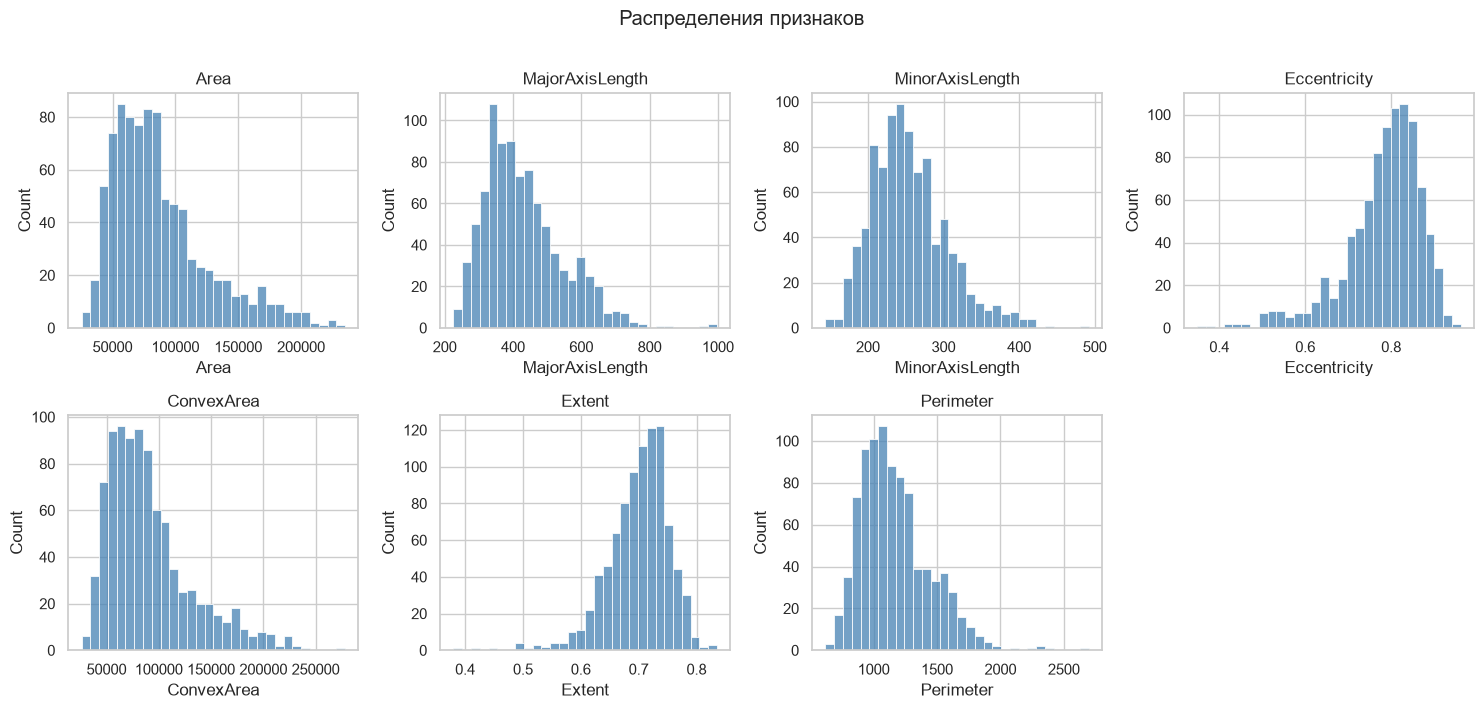

,Асимметрия
Area,1.175
MajorAxisLength,0.990
MinorAxisLength,0.800
Eccentricity,-1.328
ConvexArea,1.243
Extent,-1.152
Perimeter,1.018


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, features):
    sns.histplot(X[col], bins=30, ax=ax, color="steelblue")
    ax.set_title(col)
axes.flat[-1].axis("off")
fig.suptitle("Распределения признаков", y=1.01)
plt.tight_layout(); plt.show()
display(X.skew().rename("Асимметрия").to_frame().round(3))

Признаки размера имеют положительную асимметрию: от 0,800 для MinorAxisLength до 1,243 для ConvexArea. У Eccentricity и Extent асимметрия отрицательна (−1,328 и −1,152). Гистограммы не дают оснований считать все распределения нормальными; для выбранных алгоритмов нормальность не обязательна.

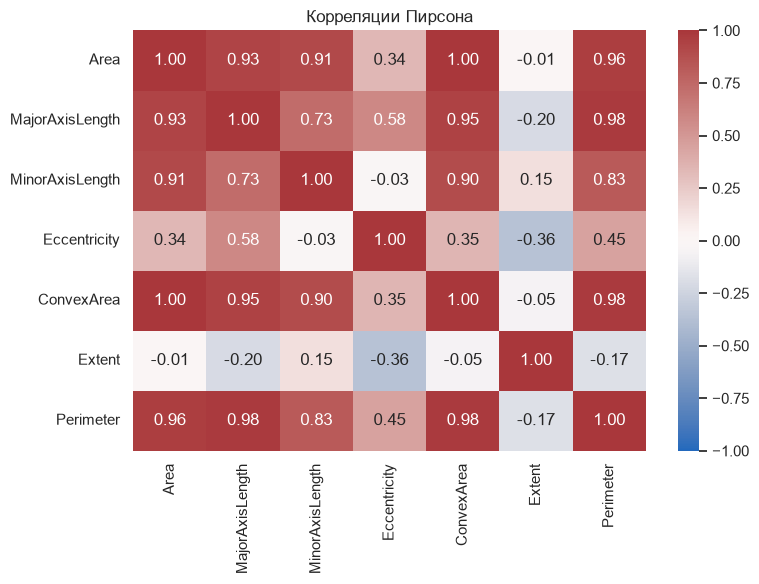

In [6]:
corr = X.corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Корреляции Пирсона"); plt.tight_layout(); plt.show()

Area и ConvexArea коррелируют на 0,996, MajorAxisLength и Perimeter — на 0,978. Эти переменные содержат частично повторяющуюся информацию о размере, поэтому в евклидовом расстоянии размер получает повышенный совокупный вес. Признаки формы дополняют описание; все признаки сохранены для интерпретации морфологии.

,За границами IQR,"Доля, %"
Area,41,4.56
MajorAxisLength,17,1.89
MinorAxisLength,26,2.89
Eccentricity,43,4.78
ConvexArea,42,4.67
Extent,21,2.33
Perimeter,17,1.89


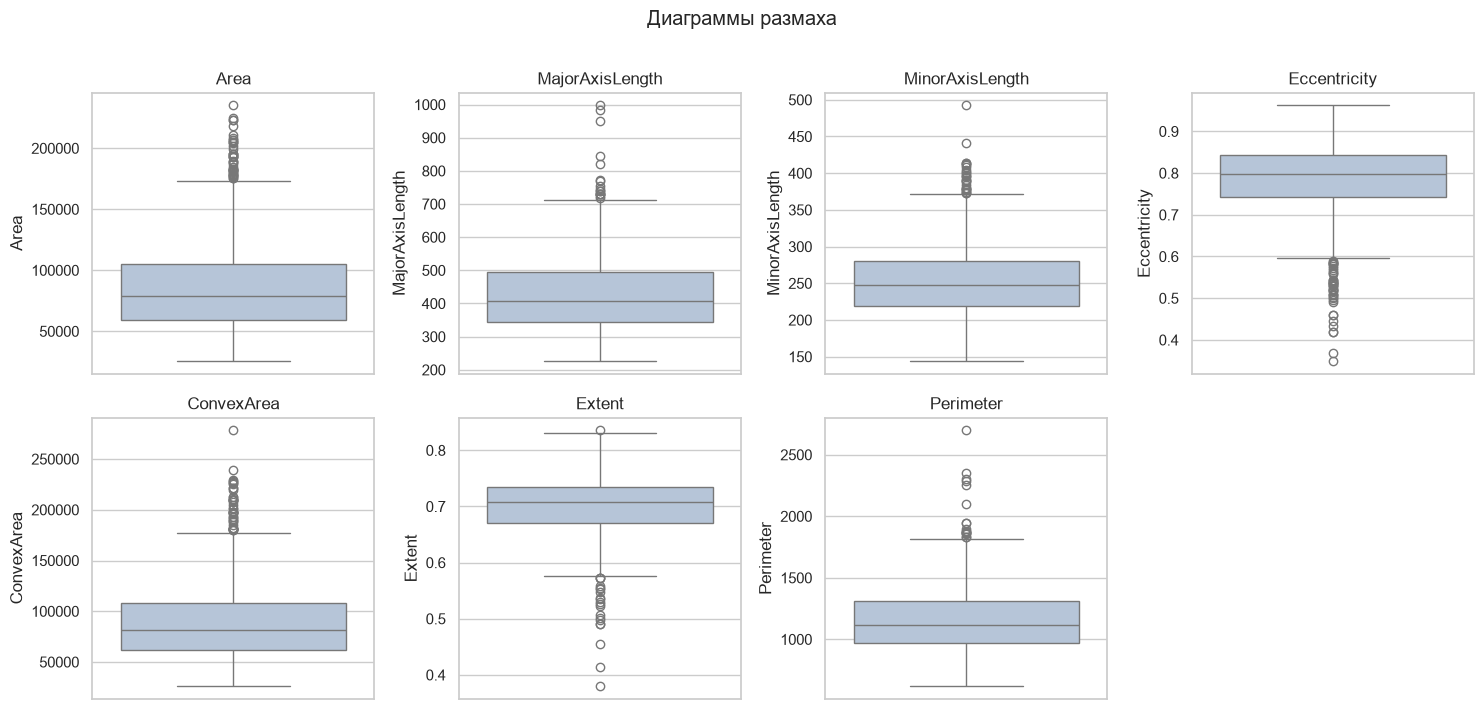

In [7]:
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
outlier_mask = (X.lt(q1 - 1.5*iqr) | X.gt(q3 + 1.5*iqr))
display(pd.DataFrame({"За границами IQR": outlier_mask.sum(), "Доля, %": 100*outlier_mask.mean()}).round(2))
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, features):
    sns.boxplot(y=X[col], ax=ax, color="lightsteelblue"); ax.set_title(col)
axes.flat[-1].axis("off"); fig.suptitle("Диаграммы размаха", y=1.01)
plt.tight_layout(); plt.show()

По правилу 1,5 IQR за границами лежат от 17 значений Perimeter и MajorAxisLength до 43 значений Eccentricity; всего отмечены 105 разных объектов. Это признаки потенциальных выбросов, а не доказательства ошибок измерения: крупные или необычные ягоды могут быть реальными. Объекты сохранены, но чувствительность средних и расстояний к крайним значениям ограничивает выводы.

Кластеризация осмысленна для поиска морфологических групп без привлечения известных меток. Разделение на сорта в данных уже задано, поэтому задача здесь исследовательская: классы сохраняются отдельно для проверки, а не считаются отсутствующими. Пропусков и выявленных дубликатов нет, но наличие потенциальных выбросов означает, что условие их полного отсутствия не выполнено.

## 2. Подготовка и структура данных

Масштабы площадей, длин и безразмерных характеристик отличаются, поэтому каждое расстояние без преобразования определялось бы главным образом площадью. StandardScaler вычитает среднее и делит на стандартное отклонение каждого признака. Сильная корреляция сохраняется и повышает общий вес группы признаков размера; это ограничение учитывается при интерпретации.

In [8]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)
check = pd.DataFrame({"Среднее": Z.mean(axis=0), "Стандартное отклонение": Z.std(axis=0)}, index=features)
display(check.round(4))

,Среднее,Стандартное отклонение
Area,0.0,1.0
MajorAxisLength,0.0,1.0
MinorAxisLength,-0.0,1.0
Eccentricity,0.0,1.0
ConvexArea,0.0,1.0
Extent,0.0,1.0
Perimeter,-0.0,1.0


После преобразования средние всех семи столбцов равны 0, а стандартные отклонения — 1 с точностью отображения. Каждый признак теперь измеряется в собственных стандартных отклонениях; корреляции и влияние крайних значений при этом сохраняются.

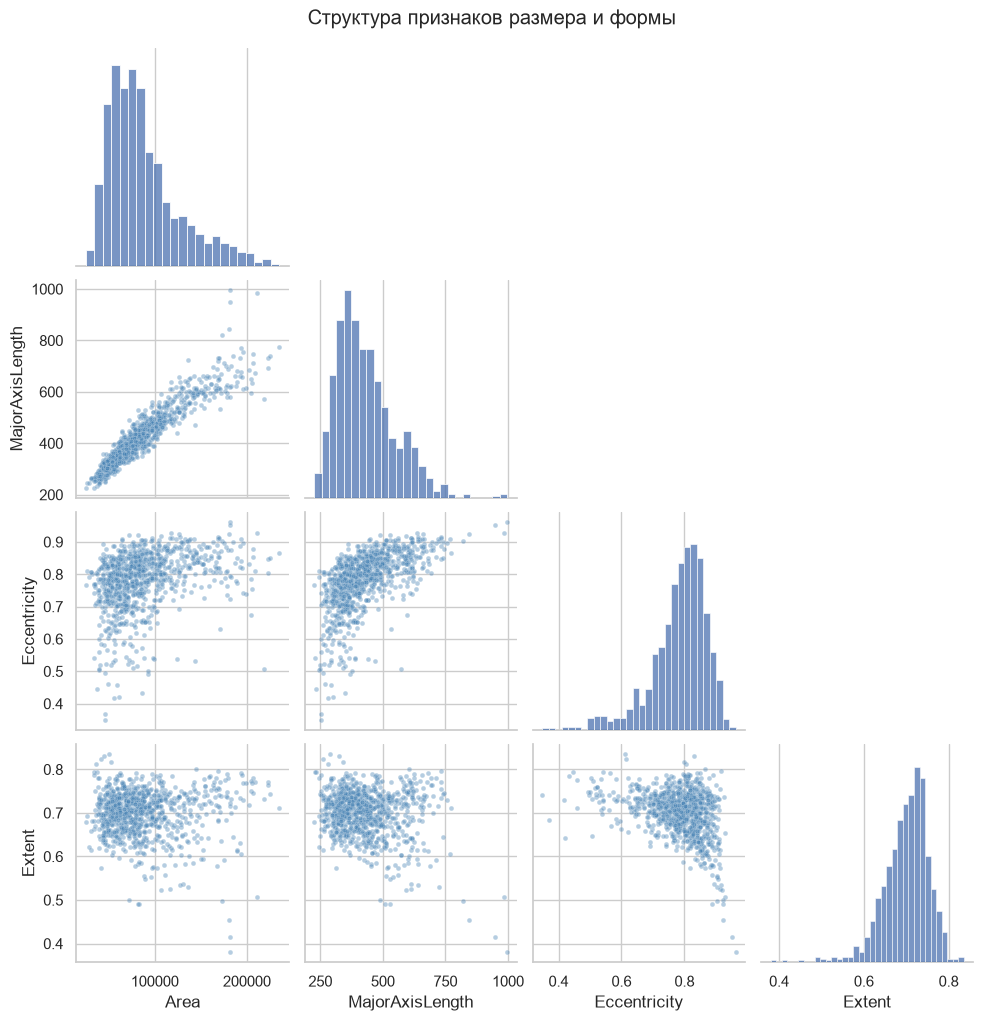

In [9]:
selected = ["Area", "MajorAxisLength", "Eccentricity", "Extent"]
sns.pairplot(X[selected], corner=True, plot_kws={"s": 12, "alpha": .4, "color": "steelblue"}, diag_kind="hist")
plt.suptitle("Структура признаков размера и формы", y=1.02); plt.show()

Area и MajorAxisLength образуют выраженную возрастающую зависимость, тогда как отношения размера с Eccentricity и Extent имеют заметный разброс. Чётких разрывов между компактными группами не видно: возможны перекрывающиеся кластеры и непрерывные переходы. Выбраны два показателя размера и два формы, чтобы не перегружать матрицу семью признаками.

## 3. K-means и выбор числа кластеров

Рассматриваются k от 2 до 10. Инерция — сумма квадратов расстояний до центров; её уменьшение при росте k само по себе не означает улучшения разбиения. Силуэт учитывает одновременно близость объектов к своему кластеру и удалённость от других.

In [10]:
ks = range(2, 11)
km_models = {k: KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z) for k in ks}
km_search = pd.DataFrame([{"k": k, "Inertia": m.inertia_, "Silhouette": silhouette_score(Z, m.labels_),
                           "Calinski–Harabasz": calinski_harabasz_score(Z, m.labels_),
                           "Davies–Bouldin": davies_bouldin_score(Z, m.labels_),
                           "Размеры": ", ".join(map(str, np.bincount(m.labels_)))} for k, m in km_models.items()]).set_index("k")
display(km_search.round(3))

,Inertia,Silhouette,Calinski–Harabasz,Davies–Bouldin,Размеры
k,,,,,
2,3397.845,0.441,766.997,0.910,"649, 251"
3,2591.651,0.309,641.755,1.101,"347, 415, 138"
4,2168.414,0.295,569.064,1.082,"150, 301, 136, 313"
5,1895.929,0.297,519.751,1.099,"280, 104, 145, 293, 78"
6,1684.055,0.273,490.085,1.071,"256, 75, 228, 144, 52, 145"
7,1496.558,0.278,477.704,1.003,"215, 266, 118, 9, 96, 76, 120"
8,1354.202,0.262,465.393,1.036,"157, 76, 177, 196, 88, 119, 80, 7"
9,1250.893,0.254,449.554,1.059,"176, 58, 76, 141, 53, 136, 6, 84, 170"
10,1148.241,0.262,443.680,1.040,"136, 46, 153, 61, 57, 6, 81, 125, 55, 180"


При k=2 силуэт максимален (0,441), индекс Calinski–Harabasz также максимален (766,997), а Davies–Bouldin минимален (0,910). При k=3 силуэт снижается до 0,309, хотя инерция уменьшается с 3397,845 до 2591,651; при больших k появляются группы размером всего 6–9 объектов. Одного снижения инерции недостаточно для выбора большего k.

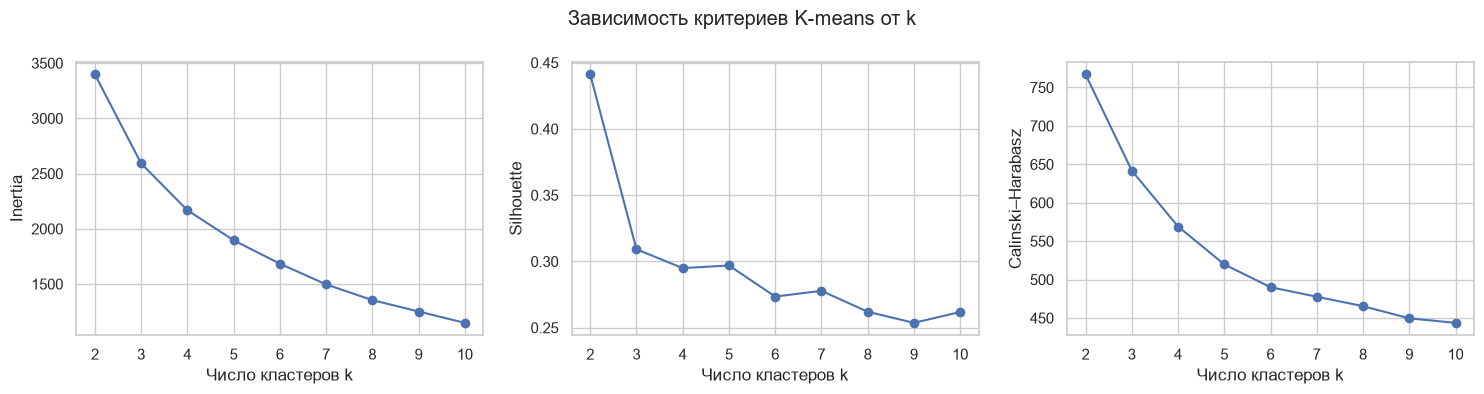

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Inertia", "Silhouette", "Calinski–Harabasz"]):
    ax.plot(km_search.index, km_search[col], marker="o"); ax.set_xlabel("Число кластеров k"); ax.set_ylabel(col); ax.set_xticks(list(ks))
fig.suptitle("Зависимость критериев K-means от k"); plt.tight_layout(); plt.show()

Самое заметное снижение инерции в показанном диапазоне происходит между k=2 и k=3; далее спад постепенно замедляется, и однозначного резкого излома нет. Силуэт и Calinski–Harabasz достигают максимума при k=2, поэтому два кластера выбраны по совокупности внутренних критериев, а не по числу сортов.

In [12]:
k_km = int(km_search["Silhouette"].idxmax())
km = km_models[k_km]; labels_km = km.labels_
print("Выбрано k =", k_km)
display(pd.Series(np.bincount(labels_km), name="Число объектов").rename_axis("Кластер").to_frame())

Выбрано k = 2


,Число объектов
Кластер,
0,649
1,251


В решении K-means получены кластеры из 649 и 251 объекта: меньший содержит около 28% выборки. Такое неравномерное разбиение отражает структуру расстояний и не предполагает равенства размеров групп.

## 4. Иерархическая кластеризация

Метод Уорда последовательно объединяет группы с минимальным приростом суммы квадратов отклонений; используется евклидово расстояние. Дендрограмма построена по всем объектам, но для читаемости показывает последние 20 объединённых групп.

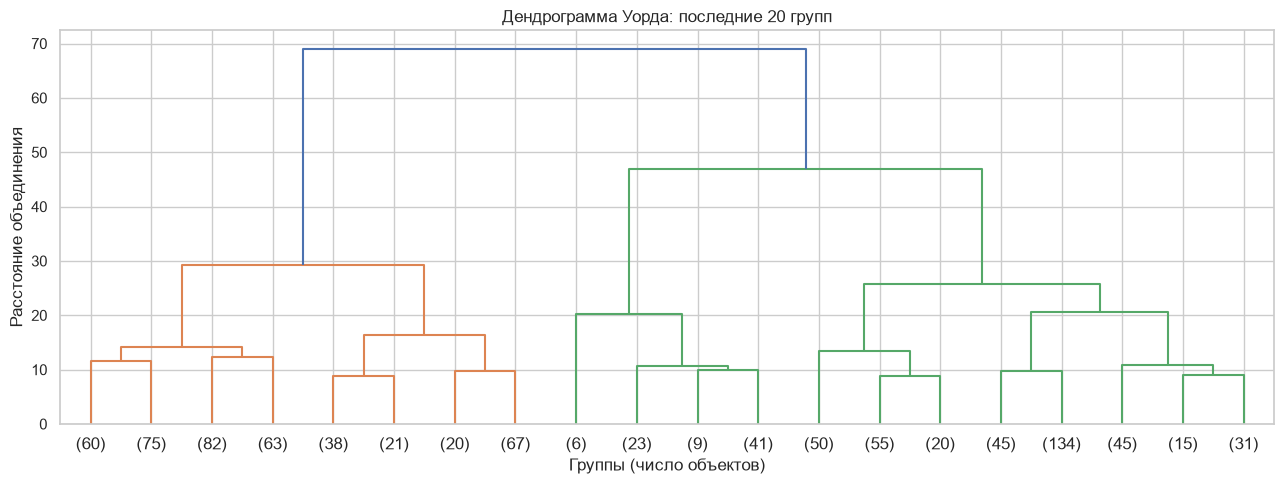

In [13]:
tree = linkage(Z, method="ward", metric="euclidean")
plt.figure(figsize=(13, 5)); dendrogram(tree, truncate_mode="lastp", p=20, show_leaf_counts=True)
plt.title("Дендрограмма Уорда: последние 20 групп"); plt.xlabel("Группы (число объектов)"); plt.ylabel("Расстояние объединения"); plt.tight_layout(); plt.show()

Последние два объединения происходят на высотах примерно 46,97 и 68,96; между ними есть заметный промежуток, допускающий разрез на две группы. Предыдущее объединение находится около 29,17, поэтому дендрограмма также допускает другие разрезы и не определяет единственное k.

,Silhouette,Calinski–Harabasz,Davies–Bouldin
k,,,
2,0.310,544.300,1.103
3,0.299,553.720,1.063
4,0.263,487.341,1.073
5,0.234,459.715,1.258
6,0.219,430.599,1.181
7,0.227,421.950,1.072
8,0.227,404.664,1.060
9,0.201,386.552,1.186
10,0.189,373.365,1.225


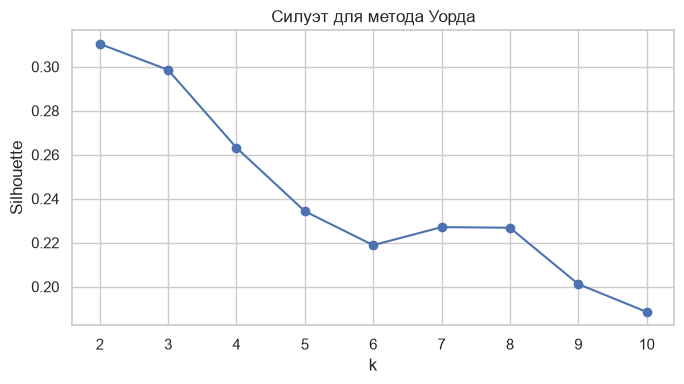

In [14]:
ward_models = {k: AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(Z) for k in ks}
ward_search = pd.DataFrame([{"k": k, "Silhouette": silhouette_score(Z, lab),
                              "Calinski–Harabasz": calinski_harabasz_score(Z, lab),
                              "Davies–Bouldin": davies_bouldin_score(Z, lab)} for k, lab in ward_models.items()]).set_index("k")
display(ward_search.round(3))
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(ward_search.index, ward_search["Silhouette"], marker="o"); ax.set_xticks(list(ks)); ax.set_xlabel("k"); ax.set_ylabel("Silhouette"); ax.set_title("Силуэт для метода Уорда"); plt.tight_layout(); plt.show()

Силуэт метода Уорда максимален при k=2 (0,310), но Calinski–Harabasz при k=3 немного выше: 553,720 против 544,300. Davies–Bouldin также меньше при k=3 (1,063 против 1,103), а его минимум в исследованном диапазоне достигается при k=8 (1,060). Критерии измеряют разные свойства и не дают одинакового оптимума; для сопоставления и с учётом силуэта и дендрограммы принято k=2.

In [15]:
k_ward = int(ward_search["Silhouette"].idxmax())
labels_ward = ward_models[k_ward]
print("Выбрано k =", k_ward)
display(pd.Series(np.bincount(labels_ward), name="Число объектов").rename_axis("Кластер").to_frame())

Выбрано k = 2


,Число объектов
Кластер,
0,474
1,426


Метод Уорда выделил группы из 474 и 426 объектов, то есть распределение заметно ровнее, чем 649 и 251 у K-means. Равномерность сама по себе не является критерием качества.

## 5. Качество и характеристики кластеров

Центроиды метода Уорда ниже — описательные средние групп, а не параметры, используемые самим алгоритмом. Все расстояния рассчитаны в одном семимерном стандартизированном пространстве. Внутрикластерное расстояние — среднее евклидово расстояние до центроида; компактность — средний квадрат такого расстояния. Межкластерное расстояние — расстояние между центроидами.

In [16]:
def cluster_details(labels):
    ids = np.unique(labels)
    centers = np.array([Z[labels == i].mean(axis=0) for i in ids])
    dist = np.linalg.norm(Z - centers[labels], axis=1)
    summary = pd.DataFrame({"Объектов": [sum(labels == i) for i in ids],
                            "Среднее расстояние": [dist[labels == i].mean() for i in ids],
                            "Средний квадрат расстояния": [(dist[labels == i]**2).mean() for i in ids]}, index=ids)
    summary.index.name = "Кластер"
    return centers, dist, summary
centers_km, dist_km, detail_km = cluster_details(labels_km)
centers_ward, dist_ward, detail_ward = cluster_details(labels_ward)
display(detail_km.round(3))
display(pd.DataFrame(squareform(pdist(centers_km)), index=range(k_km), columns=range(k_km)).round(3))

,Объектов,Среднее расстояние,Средний квадрат расстояния
Кластер,,,
0,649,1.602,3.145
1,251,2.042,5.405


,0,1
0,0.000,4.004
1,4.004,0.000


Среднее расстояние до центра равно 1,602 в кластере 0 и 2,042 в кластере 1; второй кластер менее компактен и по среднему квадрату расстояния (5,405 против 3,145). Расстояние между центрами составляет 4,004 стандартных единицы пространства признаков.

In [17]:
display(detail_ward.round(3))
display(pd.DataFrame(squareform(pdist(centers_ward)), index=range(k_ward), columns=range(k_ward)).round(3))

,Объектов,Среднее расстояние,Средний квадрат расстояния
Кластер,,,
0,474,2.09,5.734
1,426,1.50,2.828


,0,1
0,0.000,3.255
1,3.255,0.000


Для Уорда средние расстояния до описательных центроидов равны 2,090 и 1,500, а средние квадраты — 5,734 и 2,828. Первая группа более рассеяна; расстояние между центроидами равно 3,255 в том же стандартизированном пространстве.

In [18]:
def quality(labels, dist, centers):
    return {"k": len(np.unique(labels)), "Размеры кластеров": ", ".join(map(str, np.bincount(labels))),
            "Silhouette ↑": silhouette_score(Z, labels), "Calinski–Harabasz ↑": calinski_harabasz_score(Z, labels),
            "Davies–Bouldin ↓": davies_bouldin_score(Z, labels),
            "ARI ↑": adjusted_rand_score(df["Class"], labels), "NMI ↑": normalized_mutual_info_score(df["Class"], labels),
            "Среднее расстояние до центроида ↓": dist.mean(), "Средний квадрат расстояния ↓": np.mean(dist**2),
            "Среднее расстояние между центроидами": pdist(centers).mean()}
comparison = pd.DataFrame({"K-means": quality(labels_km, dist_km, centers_km), "Уорд": quality(labels_ward, dist_ward, centers_ward)}).T
display(comparison.round(3))

,k,Размеры кластеров,Silhouette ↑,Calinski–Harabasz ↑,Davies–Bouldin ↓,ARI ↑,NMI ↑,Среднее расстояние до центроида ↓,Средний квадрат расстояния ↓,Среднее расстояние между центроидами
K-means,2,"649, 251",0.441136,766.996697,0.910126,0.286181,0.337707,1.724798,3.775383,4.004261
Уорд,2,"474, 426",0.310384,544.300356,1.103001,0.414659,0.326611,1.811034,4.358316,3.255285


K-means лучше по всем трём внутренним метрикам: силуэт 0,441 против 0,310, Calinski–Harabasz 766,997 против 544,300 и Davies–Bouldin 0,910 против 1,103. Среднее расстояние до центроида также меньше (1,725 против 1,811). При внешней оценке Уорд выше по ARI (0,415 против 0,286), но ниже по NMI (0,327 против 0,338); единственного победителя по всем критериям нет.

In [19]:
print("Таблица соответствия сортов и кластеров K-means")
display(pd.crosstab(pd.Series(labels_km, name="Кластер"), df["Class"]))
print("Таблица соответствия сортов и кластеров Уорда")
display(pd.crosstab(pd.Series(labels_ward, name="Кластер"), df["Class"]))

Таблица соответствия сортов и кластеров K-means


Class,Besni,Kecimen
Кластер,,
0,204,445
1,246,5


Таблица соответствия сортов и кластеров Уорда


Class,Besni,Kecimen
Кластер,,
0,382,92
1,68,358


В K-means кластер 1 включает 246 Besni и 5 Kecimen, но в кластере 0 смешаны 204 Besni и 445 Kecimen. У Уорда соответствующие составы — 382/92 и 68/358, поэтому соответствие сортам неполное для обоих методов. Порядок меток кластеров произволен.

ARI учитывает случайное совпадение разбиений, NMI измеряет взаимную информацию с нормировкой. Номера кластеров условны и не соответствуют кодам сортов. Внешние показатели рассчитаны только после выбора k и обучения моделей.

## 6. Устойчивость

Сравниваются разбиения одних и тех же объектов с помощью ARI. Для K-means используются 10 различных значений random_state при n_init=10; затем в стандартизированные признаки добавляется независимый нормальный шум со стандартным отклонением 0,05. Для метода Уорда повторно строится разбиение на возмущённых данных. Эксперимент отражает устойчивость именно к заданному типу возмущения.

In [20]:
seeds = range(10)
rng = np.random.default_rng(2024)
init_ari = [adjusted_rand_score(labels_km, KMeans(n_clusters=k_km, random_state=s, n_init=10).fit_predict(Z)) for s in seeds]
noise_km, noise_ward = [], []
for seed in seeds:
    noisy = Z + rng.normal(0, 0.05, Z.shape)
    noise_km.append(adjusted_rand_score(labels_km, KMeans(n_clusters=k_km, random_state=42, n_init=10).fit_predict(noisy)))
    noise_ward.append(adjusted_rand_score(labels_ward, AgglomerativeClustering(n_clusters=k_ward, linkage="ward", metric="euclidean").fit_predict(noisy)))
stability = pd.DataFrame({"K-means: инициализация": init_ari, "K-means: шум": noise_km, "Уорд: шум": noise_ward})
display(stability.agg(["mean", "min", "max"]).round(3))

,K-means: инициализация,K-means: шум,Уорд: шум
mean,0.997,0.981,0.370
min,0.995,0.968,0.024
max,1.000,0.991,0.814


Для K-means средний ARI относительно базового запуска равен 0,997 при изменении инициализации и 0,981 при шуме; минимумы — 0,995 и 0,968. Для Уорда при том же уровне шума средний ARI составляет 0,370, диапазон 0,024–0,814: границы выбранного решения чувствительны к малым возмущениям. Это не доказывает устойчивость к другим видам изменений данных.

## 7. Визуализация и профили

PCA применяется только для отображения: обе модели и все метрики рассчитаны по семи стандартизированным признакам. Двумерная проекция может скрывать различия по остальным направлениям.

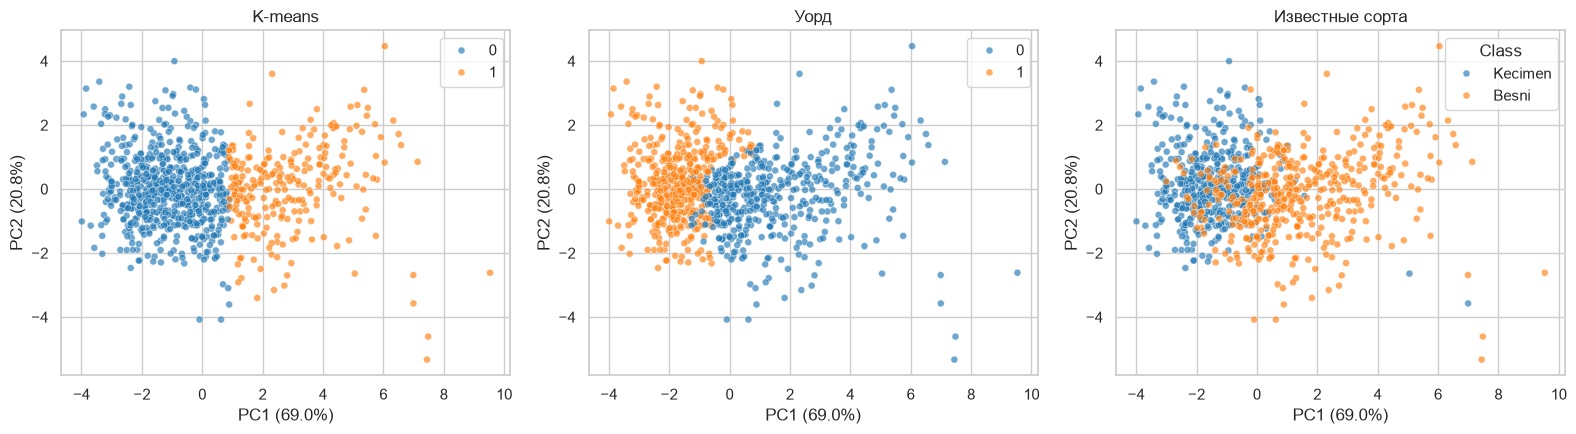

Суммарная объяснённая дисперсия: 0.8979


In [21]:
pca = PCA(n_components=2)
projection = pca.fit_transform(Z)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, labels, title in zip(axes, [labels_km, labels_ward, df["Class"]], ["K-means", "Уорд", "Известные сорта"]):
    sns.scatterplot(x=projection[:, 0], y=projection[:, 1], hue=labels, palette="tab10", s=25, alpha=.65, ax=ax)
    ax.set_title(title); ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout(); plt.show()
print("Суммарная объяснённая дисперсия:", round(pca.explained_variance_ratio_.sum(), 4))

Первые две компоненты объясняют 69,0% и 20,8% дисперсии, вместе 89,79%. Проекции групп перекрываются; в двумерном отображении часть информации (около 10,21%) не показана, поэтому качество оценивалось в исходном семимерном пространстве.

In [22]:
profiles_km = pd.DataFrame(scaler.inverse_transform(centers_km), columns=features).rename_axis("Кластер")
profiles_ward = pd.DataFrame(scaler.inverse_transform(centers_ward), columns=features).rename_axis("Кластер")
print("K-means: средние в исходных единицах")
display(profiles_km.round(3))
print("Уорд: средние в исходных единицах")
display(profiles_ward.round(3))

K-means: средние в исходных единицах


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Кластер,,,,,,,
0,67954.435,373.388,233.010,0.761,70513.569,0.702,1029.495
1,139128.633,579.713,310.024,0.833,144638.147,0.694,1518.621


Уорд: средние в исходных единицах


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
Кластер,,,,,,,
0,113036.270,513.556,280.461,0.827,117525.781,0.691,1355.304
1,59728.927,338.994,225.589,0.731,61878.547,0.709,955.169


У K-means кластер 1 характеризуется большей средней площадью (139 129 против 67 954), периметром (1519 против 1029) и эксцентриситетом (0,833 против 0,761), то есть в среднем ягоды крупнее и более вытянуты. У Уорда крупнее и вытянутее кластер 0: площадь 113 036 против 59 729 и эксцентриситет 0,827 против 0,731. Площади и длины приведены в единицах исходных измерений изображения.

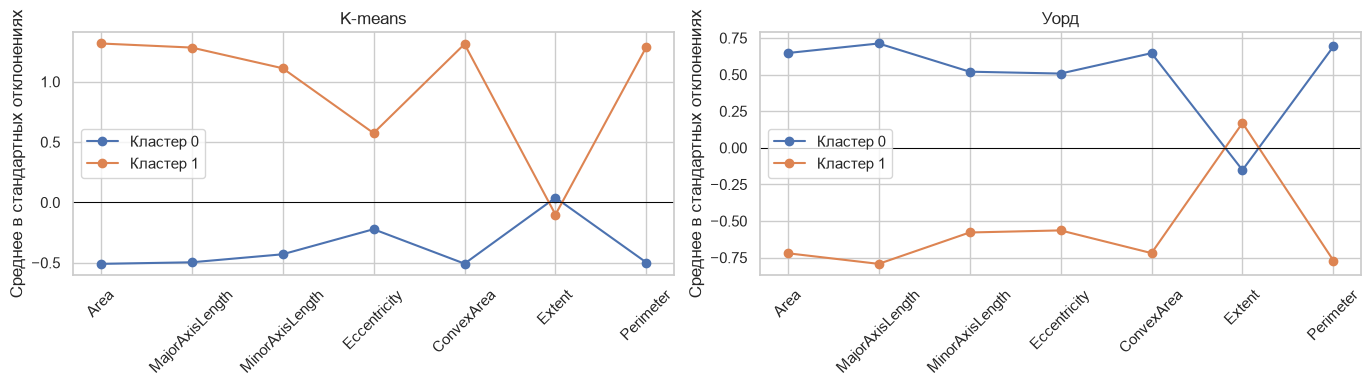

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, centers, title in zip(axes, [centers_km, centers_ward], ["K-means", "Уорд"]):
    for i, row in enumerate(centers): ax.plot(features, row, marker="o", label=f"Кластер {i}")
    ax.axhline(0, color="black", linewidth=.7); ax.set_ylabel("Среднее в стандартных отклонениях"); ax.set_title(title); ax.tick_params(axis="x", rotation=45); ax.legend()
plt.tight_layout(); plt.show()

В обоих разбиениях признаки размера изменяются согласованно, что соответствует их сильной корреляции; крупные группы также имеют более высокий средний эксцентриситет. Различие по Extent направлено в противоположную сторону и меньше по абсолютной величине стандартизированного отклонения.

## Заключение

По внутреннему силуэту для обоих методов выбраны два кластера. K-means лучше по силуэту, Calinski–Harabasz и Davies–Bouldin; у Уорда выше ARI относительно сортов, но NMI немного ниже. Группы различаются прежде всего размером и эксцентриситетом, однако сорта перекрываются. При проверенном возмущении K-means устойчив, а Уорд чувствителен; корреляция признаков размера, потенциальные выбросы и перекрытие групп ограничивают интерпретацию.

## Источники

1. UCI Machine Learning Repository. [Raisin](https://archive.ics.uci.edu/dataset/850/raisin).
2. [Копия данных Raisin Dataset в формате CSV](https://github.com/cynthiakoskei/Raisin-DataSet/blob/main/Raisin_Dataset.csv).
3. scikit-learn. [Clustering](https://scikit-learn.org/stable/modules/clustering.html).
4. scikit-learn. [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
5. SciPy. [Дендрограмма](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html).

## Приложение

Полный воспроизводимый листинг размещён в последовательных программных ячейках работы. Для запуска требуется доступ к CSV по указанному URL.